## Feature Extraction

Feature extraction is a dimensionality reduction technique that transforms raw data from its original high-dimensional space into a lower-dimensional space while preserving the most important information. 

Here's a table summarizing the key differences:

| Aspect | Feature Extraction | Feature Selection |
|--------|---------------------|-------------------|
| Output | New features | Subset of original features |
| Interpretability | Often less interpretable | Maintains original feature interpretability |
| Dimensionality Reduction | Can achieve significant reduction | Reduction limited by original feature count |
| Information Preservation | Combines information from multiple features | May lose information from unselected features |
| Use Case | When overall patterns are more important than individual features | When specific feature importance is crucial |

### Principal Component Analysis (PCA)

- Linear method
- Unsupervised method
- Projection-based method

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


In [3]:
# Load the Wine dataset

wine = load_wine()
X, y = wine.data, wine.target

In [4]:
X

array([[1.423e+01, 1.710e+00, 2.430e+00, ..., 1.040e+00, 3.920e+00,
        1.065e+03],
       [1.320e+01, 1.780e+00, 2.140e+00, ..., 1.050e+00, 3.400e+00,
        1.050e+03],
       [1.316e+01, 2.360e+00, 2.670e+00, ..., 1.030e+00, 3.170e+00,
        1.185e+03],
       ...,
       [1.327e+01, 4.280e+00, 2.260e+00, ..., 5.900e-01, 1.560e+00,
        8.350e+02],
       [1.317e+01, 2.590e+00, 2.370e+00, ..., 6.000e-01, 1.620e+00,
        8.400e+02],
       [1.413e+01, 4.100e+00, 2.740e+00, ..., 6.100e-01, 1.600e+00,
        5.600e+02]], shape=(178, 13))

In [5]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2])

In [6]:
wine.feature_names, wine.target_names

(['alcohol',
  'malic_acid',
  'ash',
  'alcalinity_of_ash',
  'magnesium',
  'total_phenols',
  'flavanoids',
  'nonflavanoid_phenols',
  'proanthocyanins',
  'color_intensity',
  'hue',
  'od280/od315_of_diluted_wines',
  'proline'],
 array(['class_0', 'class_1', 'class_2'], dtype='<U7'))

In [7]:
df = pd.concat(
    [pd.DataFrame(X, columns=wine.feature_names), pd.Series(y, name="target")], axis=1
)
df.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [8]:
df.target.value_counts()

target
1    71
0    59
2    48
Name: count, dtype: int64

In [9]:
# Standardize the features

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [10]:
X_scaled

array([[ 1.51861254, -0.5622498 ,  0.23205254, ...,  0.36217728,
         1.84791957,  1.01300893],
       [ 0.24628963, -0.49941338, -0.82799632, ...,  0.40605066,
         1.1134493 ,  0.96524152],
       [ 0.19687903,  0.02123125,  1.10933436, ...,  0.31830389,
         0.78858745,  1.39514818],
       ...,
       [ 0.33275817,  1.74474449, -0.38935541, ..., -1.61212515,
        -1.48544548,  0.28057537],
       [ 0.20923168,  0.22769377,  0.01273209, ..., -1.56825176,
        -1.40069891,  0.29649784],
       [ 1.39508604,  1.58316512,  1.36520822, ..., -1.52437837,
        -1.42894777, -0.59516041]], shape=(178, 13))

In [11]:
# Apply PCA

pca = PCA()
X_pca = pca.fit_transform(X_scaled)

In [12]:
X_pca

array([[ 3.31675081e+00,  1.44346263e+00, -1.65739045e-01, ...,
        -4.51563395e-01,  5.40810414e-01, -6.62386309e-02],
       [ 2.20946492e+00, -3.33392887e-01, -2.02645737e+00, ...,
        -1.42657306e-01,  3.88237741e-01,  3.63650247e-03],
       [ 2.51674015e+00,  1.03115130e+00,  9.82818670e-01, ...,
        -2.86672847e-01,  5.83573183e-04,  2.17165104e-02],
       ...,
       [-2.67783946e+00,  2.76089913e+00, -9.40941877e-01, ...,
         5.12492025e-01,  6.98766451e-01,  7.20776948e-02],
       [-2.38701709e+00,  2.29734668e+00, -5.50696197e-01, ...,
         2.99821968e-01,  3.39820654e-01, -2.18657605e-02],
       [-3.20875816e+00,  2.76891957e+00,  1.01391366e+00, ...,
        -2.29964331e-01, -1.88787963e-01, -3.23964720e-01]],
      shape=(178, 13))

Text(0.5, 1.0, 'Wine Dataset: First Two Principal Components')

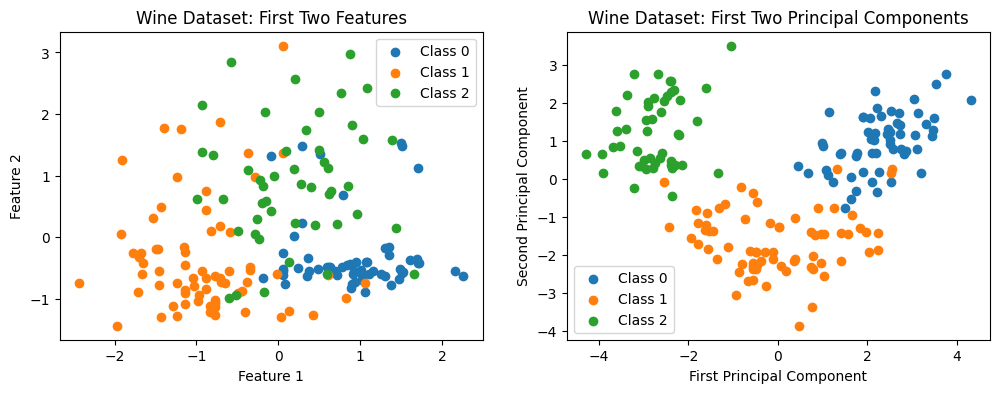

In [13]:
# Plot the first two principal components

fig, axs = plt.subplots(1, 2, figsize=(12, 4))
for i in range(3):
    axs[0].scatter(X_scaled[y == i, 0], X_scaled[y == i, 1], label=f"Class {i}")
axs[0].set_xlabel("Feature 1")
axs[0].set_ylabel("Feature 2")
axs[0].legend()
axs[0].set_title("Wine Dataset: First Two Features")

# Plot the first two principal components

plt.subplot(1, 2, 2)
for i in range(3):
    axs[1].scatter(X_pca[y == i, 0], X_pca[y == i, 1], label=f"Class {i}")
axs[1].set_xlabel("First Principal Component")
axs[1].set_ylabel("Second Principal Component")
axs[1].legend()
axs[1].set_title("Wine Dataset: First Two Principal Components")

Text(0.5, 1.0, 'Explained Variance Ratio vs. Number of Components')

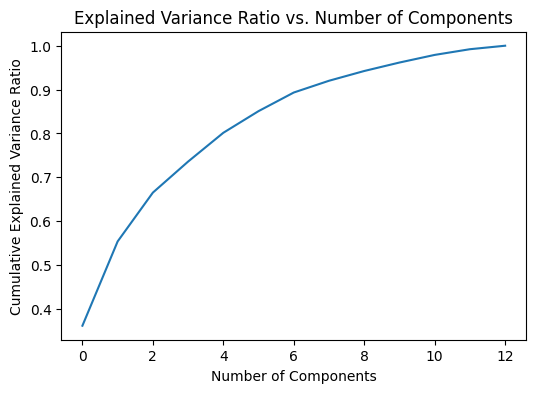

In [14]:
# Plot the cumulative explained variance ratio

plt.figure(figsize=(6, 4))
plt.plot(np.cumsum(pca.explained_variance_ratio_))
plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance Ratio")
plt.title("Explained Variance Ratio vs. Number of Components")

### Interpreting PCA Results

1. **Explained Variance Ratio:** This tells us how much of the total variance in the data is explained by each principal component.

In [15]:
print("Explained variance ratio:", pca.explained_variance_ratio_)

Explained variance ratio: [0.36198848 0.1920749  0.11123631 0.0706903  0.06563294 0.04935823
 0.04238679 0.02680749 0.02222153 0.01930019 0.01736836 0.01298233
 0.00795215]


In [16]:
pca.explained_variance_ratio_.sum()

np.float64(1.0)

In [17]:
# Cumulative Explained Variance

cumulative_variance_ratio = np.cumsum(pca.explained_variance_ratio_)
n_components_95 = np.argmax(cumulative_variance_ratio >= 0.95) + 1
print(f"Number of components explaining 95% of variance: {n_components_95}")

Number of components explaining 95% of variance: 10


In [18]:
component_loadings = pd.DataFrame(
    pca.components_.T,
    columns=[f"PC{i+1}" for i in range(pca.n_components_)],
    index=wine.feature_names,
)
print("Component loadings:")
component_loadings.style.highlight_max(
    axis=0, props="background-color: green; color: black"
)

Component loadings:


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13
alcohol,0.144329,0.483652,-0.207383,-0.017856,-0.265664,0.213539,-0.056396,0.396139,-0.508619,0.211605,-0.225917,-0.266286,0.014970
malic_acid,-0.245188,0.224931,0.089013,0.536890,0.035214,0.536814,0.420524,0.065827,0.075283,-0.309080,0.076486,0.121696,0.025964
ash,-0.002051,0.316069,0.626224,-0.214176,-0.143025,0.154475,-0.149171,-0.170260,0.307694,-0.027125,-0.498691,-0.049622,-0.141218
alcalinity_of_ash,-0.239320,-0.010591,0.612080,0.060859,0.066103,-0.100825,-0.286969,0.427970,-0.200449,0.052799,0.479314,-0.055743,0.091683
magnesium,0.141992,0.299634,0.130757,-0.351797,0.727049,0.038144,0.322883,-0.156361,-0.271403,0.067870,0.071289,0.062220,0.056774
total_phenols,0.394661,0.065040,0.146179,0.198068,-0.149318,-0.084122,-0.027925,-0.405934,-0.286035,-0.320131,0.304341,-0.303882,-0.463908
flavanoids,0.422934,-0.003360,0.150682,0.152295,-0.109026,-0.018920,-0.060685,-0.187245,-0.049578,-0.163151,-0.025694,-0.042899,0.832257
nonflavanoid_phenols,-0.298533,0.028779,0.170368,-0.203301,-0.500703,-0.258594,0.595447,-0.233285,-0.195501,0.215535,0.116896,0.042352,0.114040
proanthocyanins,0.313429,0.039302,0.149454,0.399057,0.136860,-0.533795,0.372139,0.368227,0.209145,0.134184,-0.237363,-0.095553,-0.116917
color_intensity,-0.088617,0.529996,-0.137306,0.065926,-0.076437,-0.418644,-0.227712,-0.033797,-0.056218,-0.290775,0.031839,0.604222,-0.011993


In [19]:
df.corr()['target']

alcohol                        -0.328222
malic_acid                      0.437776
ash                            -0.049643
alcalinity_of_ash               0.517859
magnesium                      -0.209179
total_phenols                  -0.719163
flavanoids                     -0.847498
nonflavanoid_phenols            0.489109
proanthocyanins                -0.499130
color_intensity                 0.265668
hue                            -0.617369
od280/od315_of_diluted_wines   -0.788230
proline                        -0.633717
target                          1.000000
Name: target, dtype: float64

### Linear Discriminant Analysis (LDA)

- Linear method
- Supervised method
- Projection-based method

#### LDA Concept and How it Differs from PCA :
While both LDA and PCA are linear transformation techniques, their objectives differ:

1. **Objective:**
   - PCA aims to find the axes that maximize the variance in the data.
   - LDA aims to find the axes that maximize the separation between classes.

2. **Supervision:**
   - PCA is unsupervised and does not use class labels.
   - LDA is supervised and explicitly uses class label information.

3. **Optimization Criterion:**
   - PCA maximizes the variance of the projected data.
   - LDA maximizes the ratio of between-class variance to within-class variance.

4. **Number of Components:**
   - PCA can produce as many components as the original features.
   - LDA can produce at most C-1 components, where C is the number of classes.

In [20]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

# Apply LDA

lda = LinearDiscriminantAnalysis()
X_lda = lda.fit_transform(X_scaled, y)
X_lda.shape

(178, 2)

In [21]:
X_lda

array([[-4.70024401,  1.97913835],
       [-4.30195811,  1.17041286],
       [-3.42071952,  1.42910139],
       [-4.20575366,  4.00287148],
       [-1.50998168,  0.4512239 ],
       [-4.51868934,  3.21313756],
       [-4.52737794,  3.26912179],
       [-4.14834781,  3.10411765],
       [-3.86082876,  1.95338263],
       [-3.36662444,  1.67864327],
       [-4.80587907,  2.23536271],
       [-3.42807646,  2.17510939],
       [-3.66610246,  2.26248961],
       [-5.58824635,  2.05478773],
       [-5.50131449,  3.61304865],
       [-3.18475189,  2.88952528],
       [-3.28936988,  2.76584266],
       [-2.99809262,  1.42511132],
       [-5.24640372,  3.70982655],
       [-3.13653106,  1.97689922],
       [-3.57747791,  0.5624599 ],
       [-1.69077135,  0.91342136],
       [-4.83515033,  0.9147628 ],
       [-3.09588961,  0.61735888],
       [-3.32164716,  0.29847734],
       [-2.14482223,  0.16369247],
       [-3.9824285 ,  2.17515679],
       [-2.68591432,  1.21850924],
       [-3.56309464,

In [22]:
# Apply PCA for comparison

pca = PCA()
X_pca = pca.fit_transform(X_scaled)
X_pca

array([[ 3.31675081e+00,  1.44346263e+00, -1.65739045e-01, ...,
        -4.51563395e-01,  5.40810414e-01, -6.62386309e-02],
       [ 2.20946492e+00, -3.33392887e-01, -2.02645737e+00, ...,
        -1.42657306e-01,  3.88237741e-01,  3.63650247e-03],
       [ 2.51674015e+00,  1.03115130e+00,  9.82818670e-01, ...,
        -2.86672847e-01,  5.83573183e-04,  2.17165104e-02],
       ...,
       [-2.67783946e+00,  2.76089913e+00, -9.40941877e-01, ...,
         5.12492025e-01,  6.98766451e-01,  7.20776948e-02],
       [-2.38701709e+00,  2.29734668e+00, -5.50696197e-01, ...,
         2.99821968e-01,  3.39820654e-01, -2.18657605e-02],
       [-3.20875816e+00,  2.76891957e+00,  1.01391366e+00, ...,
        -2.29964331e-01, -1.88787963e-01, -3.23964720e-01]],
      shape=(178, 13))

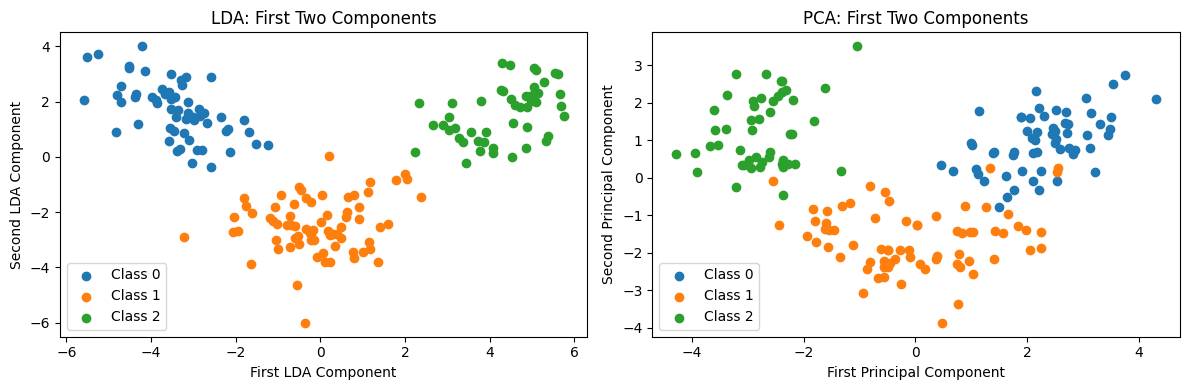

In [23]:
# Plot LDA vs PCA

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

for i in range(3):
    ax1.scatter(X_lda[y == i, 0], X_lda[y == i, 1], label=f"Class {i}")
ax1.set_xlabel("First LDA Component")
ax1.set_ylabel("Second LDA Component")
ax1.legend()
ax1.set_title("LDA: First Two Components")

for i in range(3):
    ax2.scatter(X_pca[y == i, 0], X_pca[y == i, 1], label=f"Class {i}")
ax2.set_xlabel("First Principal Component")
ax2.set_ylabel("Second Principal Component")
ax2.legend()
ax2.set_title("PCA: First Two Components")

plt.tight_layout()

In [24]:
# Print explained variance ratio for LDA

print("LDA explained variance ratio:", lda.explained_variance_ratio_)

LDA explained variance ratio: [0.68747889 0.31252111]


In [25]:
# Print explained variance ratio for PCA

print("PCA explained variance ratio:", pca.explained_variance_ratio_[:2])

PCA explained variance ratio: [0.36198848 0.1920749 ]


### Interpreting LDA Results

1. **Explained Variance Ratio:** This shows how much of the between-class variance is explained by each discriminant component.

2. **Visualization:** The scatter plot of the first two LDA components often shows better class separation compared to PCA, especially for classification tasks.

3. **Coefficients:** These show how each original feature contributes to each discriminant component.

In [26]:
lda_coefficients = pd.DataFrame(
    np.abs(lda.scalings_),
    columns=[f"LD{i+1}" for i in range(lda.scalings_.shape[1])],
    index=wine.feature_names,
)
print("LDA coefficients:")
lda_coefficients.style.highlight_max(
    axis=0, props="background-color: green; color: black"
)

LDA coefficients:


,LD1,LD2
alcohol,0.326569,0.705754
malic_acid,0.184094,0.340194
ash,0.100969,0.641759
alcalinity_of_ash,0.515503,0.487473
magnesium,0.030813,0.006591
total_phenols,0.385720,0.020104
flavanoids,1.654628,0.490054
nonflavanoid_phenols,0.185636,0.202407
proanthocyanins,0.076533,0.175270
color_intensity,0.820805,0.585410


In [27]:
df.corr()['target']

alcohol                        -0.328222
malic_acid                      0.437776
ash                            -0.049643
alcalinity_of_ash               0.517859
magnesium                      -0.209179
total_phenols                  -0.719163
flavanoids                     -0.847498
nonflavanoid_phenols            0.489109
proanthocyanins                -0.499130
color_intensity                 0.265668
hue                            -0.617369
od280/od315_of_diluted_wines   -0.788230
proline                        -0.633717
target                          1.000000
Name: target, dtype: float64

### t-SNE (t-Distributed Stochastic Neighbor Embedding)

#### How t-SNE Works:

t-SNE algorithm looks for a mapping between the high-dimensional data and a low-dimensional embedding such that the similarity between points in the high-dimensional space is preserved in the low-dimensional space.

1. **Probability Distribution in High-Dimensional Space:**
   t-SNE starts by computing the probability of similarity between points in the high-dimensional space. For each pair of points, it calculates the conditional probability that a point would choose another point as its neighbor if neighbors were picked in proportion to their probability density under a Gaussian centered at the first point.

2. **Probability Distribution in Low-Dimensional Space:**
   It then constructs a similar probability distribution for the points in the low-dimensional space, using a Student t-distribution instead of a Gaussian.

3. **Minimizing Divergence:**
   The algorithm then minimizes the Kullback-Leibler divergence between these two distributions with respect to the locations of the points in the low-dimensional space. This process moves the points in the low-dimensional space to minimize this divergence, effectively preserving the local structure of the high-dimensional data.

Text(0, 0.5, 't-SNE feature 2')

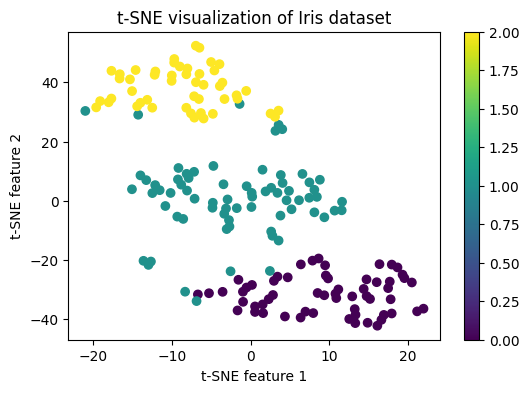

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE

# Apply t-SNE

tsne = TSNE(n_components=2, random_state=42, perplexity=10)
X_tsne = tsne.fit_transform(X_scaled)

# Visualize the result

plt.figure(figsize=(6, 4))
scatter = plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap="viridis")
plt.colorbar(scatter)
plt.title("t-SNE visualization of Iris dataset")
plt.xlabel("t-SNE feature 1")
plt.ylabel("t-SNE feature 2")

In [29]:
X_tsne

array([[  8.51029   , -31.214775  ],
       [ 16.3732    , -21.46753   ],
       [  6.3486547 , -39.51884   ],
       [ 12.528091  , -39.99748   ],
       [ -5.293444  , -31.287865  ],
       [ 14.863359  , -41.27617   ],
       [ 17.67747   , -27.365166  ],
       [ -0.9625445 , -34.19718   ],
       [ 17.468122  , -29.566975  ],
       [ 15.168371  , -33.2263    ],
       [ 17.92399   , -38.133564  ],
       [ 19.300346  , -25.01625   ],
       [ 19.54011   , -26.191885  ],
       [ 21.96306   , -36.510475  ],
       [ 21.151342  , -37.417667  ],
       [  1.530181  , -35.073265  ],
       [  1.5842491 , -38.017097  ],
       [  0.55526924, -37.625492  ],
       [ 16.099169  , -42.275066  ],
       [  9.55239   , -25.293835  ],
       [  9.357359  , -31.974524  ],
       [  6.3787303 , -21.54786   ],
       [ 14.721919  , -26.609974  ],
       [  2.9570518 , -27.109396  ],
       [  3.4096067 , -25.680632  ],
       [ -6.704084  , -31.693617  ],
       [  2.838957  , -31.889046  ],
 

Combine with Other Methods: Consider using t-SNE in conjunction with other dimensionality reduction techniques. For example, you might use PCA to reduce to an intermediate dimensionality before applying t-SNE.



In [30]:
# First reduce to 50 dimensions with PCA

pca = PCA(n_components=10)
X_pca = pca.fit_transform(X)
X_pca.shape

(178, 10)

In [31]:
# Then apply t-SNE

tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_pca)
X_tsne.shape

(178, 2)

### Autoencoders for Feature Extraction

#### Structure of an Autoencoder:

1. **Encoder:** The part of the network that compresses the input into a latent-space representation.
2. **Bottleneck:** The layer with the compressed representation of the input data.
3. **Decoder:** The part that aims to reconstruct the input from the latent space representation.

### Building and Training an Autoencoder for Feature Extraction

In [32]:
%pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [33]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.optimizers import Adam

I0000 00:00:1793924943.517629   14390 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793924945.684255   14390 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793924948.752748   14390 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [34]:
# Load and preprocess the MNIST dataset

(x_train, _), (x_test, _) = mnist.load_data()
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0
x_train = x_train.reshape((len(x_train), np.prod(x_train.shape[1:])))
x_test = x_test.reshape((len(x_test), np.prod(x_test.shape[1:])))

In [35]:
x_train.shape, x_test.shape

((60000, 784), (10000, 784))

In [36]:
# Define the autoencoder architecture

input_dim = x_train.shape[1]
encoding_dim = 32  # Size of the encoded representation

In [37]:
input_img = Input(shape=(input_dim,))
encoded = Dense(128, activation="relu")(input_img)
encoded = Dense(64, activation="relu")(encoded)
encoded = Dense(encoding_dim, activation="relu")(encoded)

decoded = Dense(64, activation="relu")(encoded)
decoded = Dense(128, activation="relu")(decoded)
decoded = Dense(input_dim, activation="sigmoid")(decoded)

E0000 00:00:1793924954.131385   14390 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


In [38]:
# Create the autoencoder model

autoencoder = Model(input_img, decoded)
encoder = Model(input_img, encoded)

In [39]:
# Compile and train the autoencoder

autoencoder.compile(optimizer=Adam(), loss="binary_crossentropy")
history = autoencoder.fit(
    x_train,
    x_train,
    epochs=50,
    batch_size=256,
    shuffle=True,
    validation_data=(x_test, x_test),
)

W0000 00:00:1793924956.232506   14390 cpu_allocator_impl.cc:82] Allocation of 188160000 exceeds 10% of free system memory.
W0000 00:00:1793924957.791075   14390 cpu_allocator_impl.cc:82] Allocation of 188160000 exceeds 10% of free system memory.


Epoch 1/50
234/235 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.3378

W0000 00:00:1793924962.990111   14390 cpu_allocator_impl.cc:82] Allocation of 31360000 exceeds 10% of free system memory.


235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - loss: 0.2448 - val_loss: 0.1691
Epoch 2/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.1525 - val_loss: 0.1384
Epoch 3/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.1326 - val_loss: 0.1246
Epoch 4/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.1225 - val_loss: 0.1177
Epoch 5/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.1165 - val_loss: 0.1126
Epoch 6/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.1118 - val_loss: 0.1089
Epoch 7/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.1083 - val_loss: 0.1055
Epoch 8/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.1056 - val_loss: 0.1033
Epoch 9/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.1034 - val_loss: 0.1011
Epoch 10/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.1014 - val_loss: 0.0992
Epoch 11/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss: 0.0996 - val_loss: 0.0980
Epoch 12/50
235/235 ━━━━━━━━━━━━━━━━━━━━ 2s 8ms/step - loss:

In [40]:
# Extract features using the trained encoder

encoded_imgs = encoder.predict(x_test)

 63/313 ━━━━━━━━━━━━━━━━━━━━ 0s 813us/step

W0000 00:00:1793925066.536526   14390 cpu_allocator_impl.cc:82] Allocation of 31360000 exceeds 10% of free system memory.


313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step


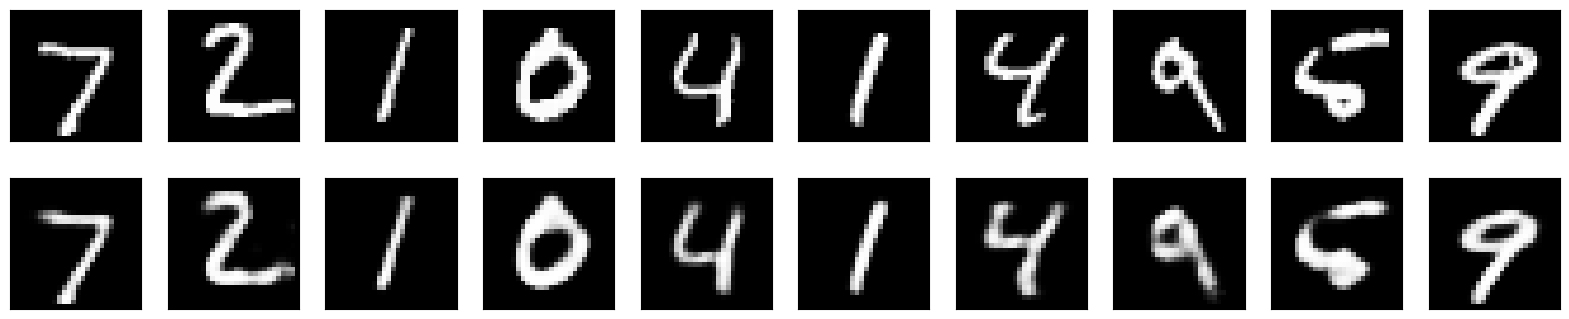

In [41]:
# Visualize the original and reconstructed images

n = 10
plt.figure(figsize=(20, 4))
for i in range(n):
    # Original
    
    ax = plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i].reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)

    # Reconstruction
    
    ax = plt.subplot(2, n, i + 1 + n)
    plt.imshow(autoencoder.predict(x_test[i].reshape(1, 784)).reshape(28, 28))
    plt.gray()
    ax.get_xaxis().set_visible(False)
    ax.get_yaxis().set_visible(False)
plt.show()

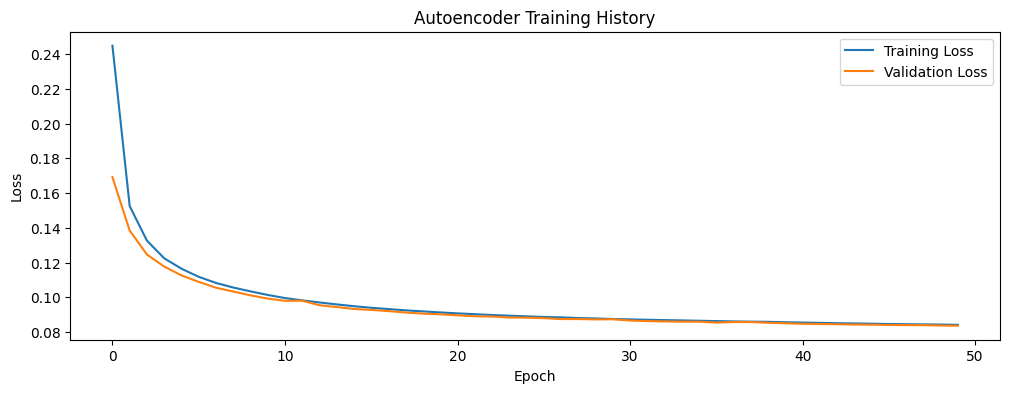

In [42]:
# Plot the training history

plt.figure(figsize=(12, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Autoencoder Training History")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

## Evaluating Extracted Features

- Reconstruction Error
- Explained Variance Ratio (for PCA)
- Silhouette Score
- Downstream Task Performance
- Visualizing High-Dimensional Data After Extraction

In [43]:
from sklearn.metrics import silhouette_score

# Assuming X_extracted are your extracted features and y are the labels

silhouette_avg = silhouette_score(X_pca, y)
print(f"Silhouette Score: {silhouette_avg}")

Silhouette Score: 0.2000839829893727


In [44]:
silhouette_avg = silhouette_score(X_tsne, y)
print(f"Silhouette Score: {silhouette_avg}")


Silhouette Score: 0.25829365849494934


In [45]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# Split the data

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train_pca, X_test_pca, y_train_pca, y_test_pca = train_test_split(X_pca, y, test_size=0.2, random_state=42)

# Train and evaluate with original features

svm_original = SVC().fit(X_train, y_train)
accuracy_original = accuracy_score(y_test, svm_original.predict(X_test))

# Train and evaluate with extracted features

svm_extracted = SVC().fit(X_train_pca, y_train_pca)
accuracy_extracted = accuracy_score(y_test_pca, svm_extracted.predict(X_test_pca))

print(f"Accuracy with original features: {accuracy_original}")
print(f"Accuracy with extracted features: {accuracy_extracted}")

Accuracy with original features: 0.8055555555555556
Accuracy with extracted features: 0.7777777777777778


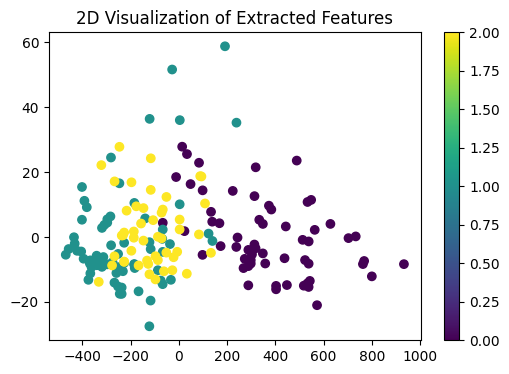

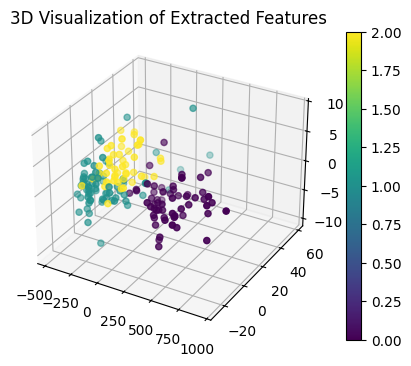

In [46]:
import matplotlib.pyplot as plt

# For 2D

plt.figure(figsize=(6, 4))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis')
plt.colorbar()
plt.title('2D Visualization of Extracted Features')
plt.show()

# For 3D

fig = plt.figure(figsize=(6, 4))
ax = fig.add_subplot(111, projection='3d')
scatter = ax.scatter(X_pca[:, 0], X_pca[:, 1], X_pca[:, 2], c=y, cmap='viridis')
plt.colorbar(scatter)
plt.title('3D Visualization of Extracted Features')
plt.show()

Text(0.5, 1.0, 't-SNE Visualization of Extracted Features')

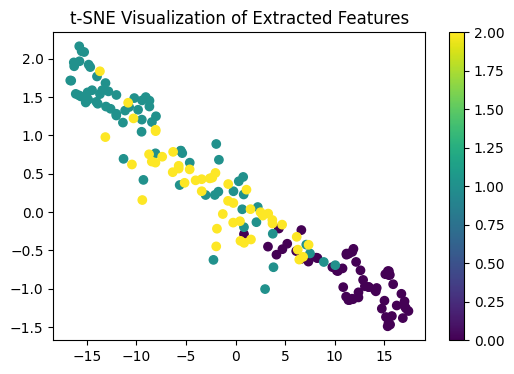

In [47]:
# t-SNE for Higher Dimensions

from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X)

plt.figure(figsize=(6, 4))
plt.scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap='viridis')
plt.colorbar()
plt.title('t-SNE Visualization of Extracted Features')

In [48]:
# Pairwise Feature Plots

import seaborn as sns

# Assuming X_extracted is a DataFrame

df_tsne = pd.DataFrame(X_tsne, columns=[f"PC{i}" for i in range(X_tsne.shape[1])])
df_tsne['y'] = y

df_tsne

,PC0,PC1,y
0,11.885133,-0.480538,0
1,11.506394,-1.147849,0
2,14.050035,-1.015527,0
3,16.863930,-1.384284,0
4,3.268320,-0.451542,0
...,...,...,...
173,3.289910,-0.019914,2
174,3.707676,-0.103938,2
175,6.272249,-0.490825,2
176,6.423851,-0.620846,2


Text(0.5, 1.02, 'Pairwise Plots of Extracted Features')

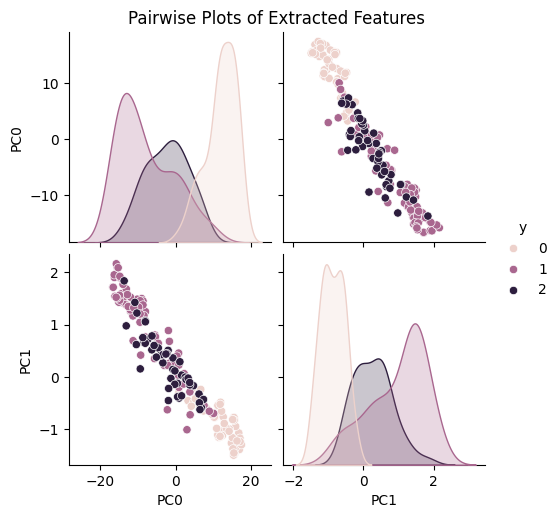

In [49]:
sns.pairplot(df_tsne, hue='y', diag_kind='kde')
plt.suptitle('Pairwise Plots of Extracted Features', y=1.02)

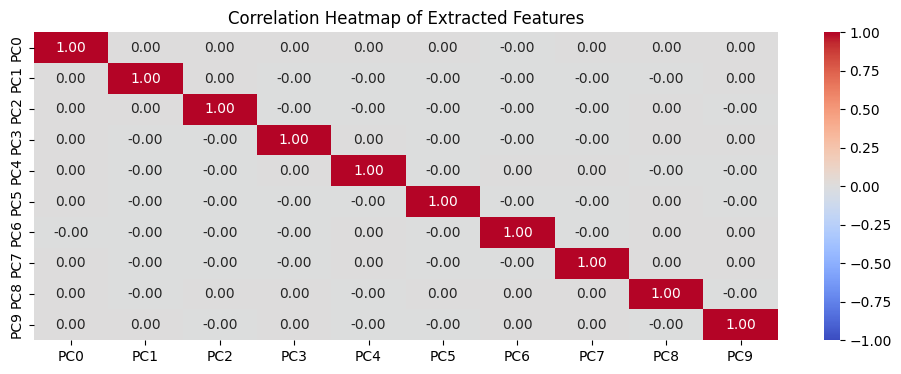

In [50]:
# Heatmaps

df_pca = pd.DataFrame(X_pca, columns=[f"PC{i}" for i in range(X_pca.shape[1])])
correlation_matrix = df_pca.corr()

plt.figure(figsize=(12, 4))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, center=0, fmt='.2f')
plt.title('Correlation Heatmap of Extracted Features')
plt.show()